In [40]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
import phik


load_dotenv(find_dotenv(usecwd=True))
url = URL.create("postgresql+psycopg2",
    username=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
    host="localhost", port=5433, database="hotel")
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM hotels", engine)

print(df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['is_canceled'].mean())



(119390, 32)
(87396, 32)
0.27489816467572886


In [41]:
print("дублей:", df.duplicated().sum(), f"({df.duplicated().mean():.1%})")

vc = df.value_counts(dropna=False)
print(vc[vc > 1].describe())          # сколько копий у повторяющихся строк

mask = df.duplicated(keep=False)
print("доля отмен среди дублей:", df.loc[mask, "is_canceled"].mean())
print("доля отмен во всём датасете:", df["is_canceled"].mean())

дублей: 0 (0.0%)
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: count, dtype: float64
доля отмен среди дублей: nan
доля отмен во всём датасете: 0.27489816467572886


interval columns not set, guessing: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5, 21.5,
        22.5, 23.5, 24.5, 25.5, 26.5, 27.5, 28.5, 29.5, 30.5, 31.5]),
 [Text(0, 0.5, 'hotel'),
  Text(0, 1.5, 'is_canceled'),
  Text(0, 2.5, 'lead_time'),
  Text(0, 3.5, 'arrival_date_year'),
  Text(0, 4.5, 'arrival_date_month'),
  Text(0, 5.5, 'arrival_date_week_number'),
  Text(0, 6.5, 'arrival_date_day_of_month'),
  Text(0, 7.5, 'stays_in_weekend_nights'),
  Text(0, 8.5, 'stays_in_week_nights'),
  Text(0, 9.5, 'adults'),
  Text(0, 10.5, 'children'),
  Text(0, 11.5, 'babies'),
  Text(0, 12.5, 'meal'),
  Text(0, 13.5, 'country'),
  Text(0, 14.5, 'market_segment'),
  Text(0, 15.5, 'distribution_channel'),
  Text(0, 16.5, 'is_repeated_guest'),
  Text(0, 17.5, 'previous_cancellations'),
  Text(0, 18.5, 'previous_bookings_not_canceled'),
  Text(0, 19.5, 'reserved_room_type'),
  Text(0, 20.5, 'assigned_room_type'),
  Text(0, 21.5, 'booking_chan

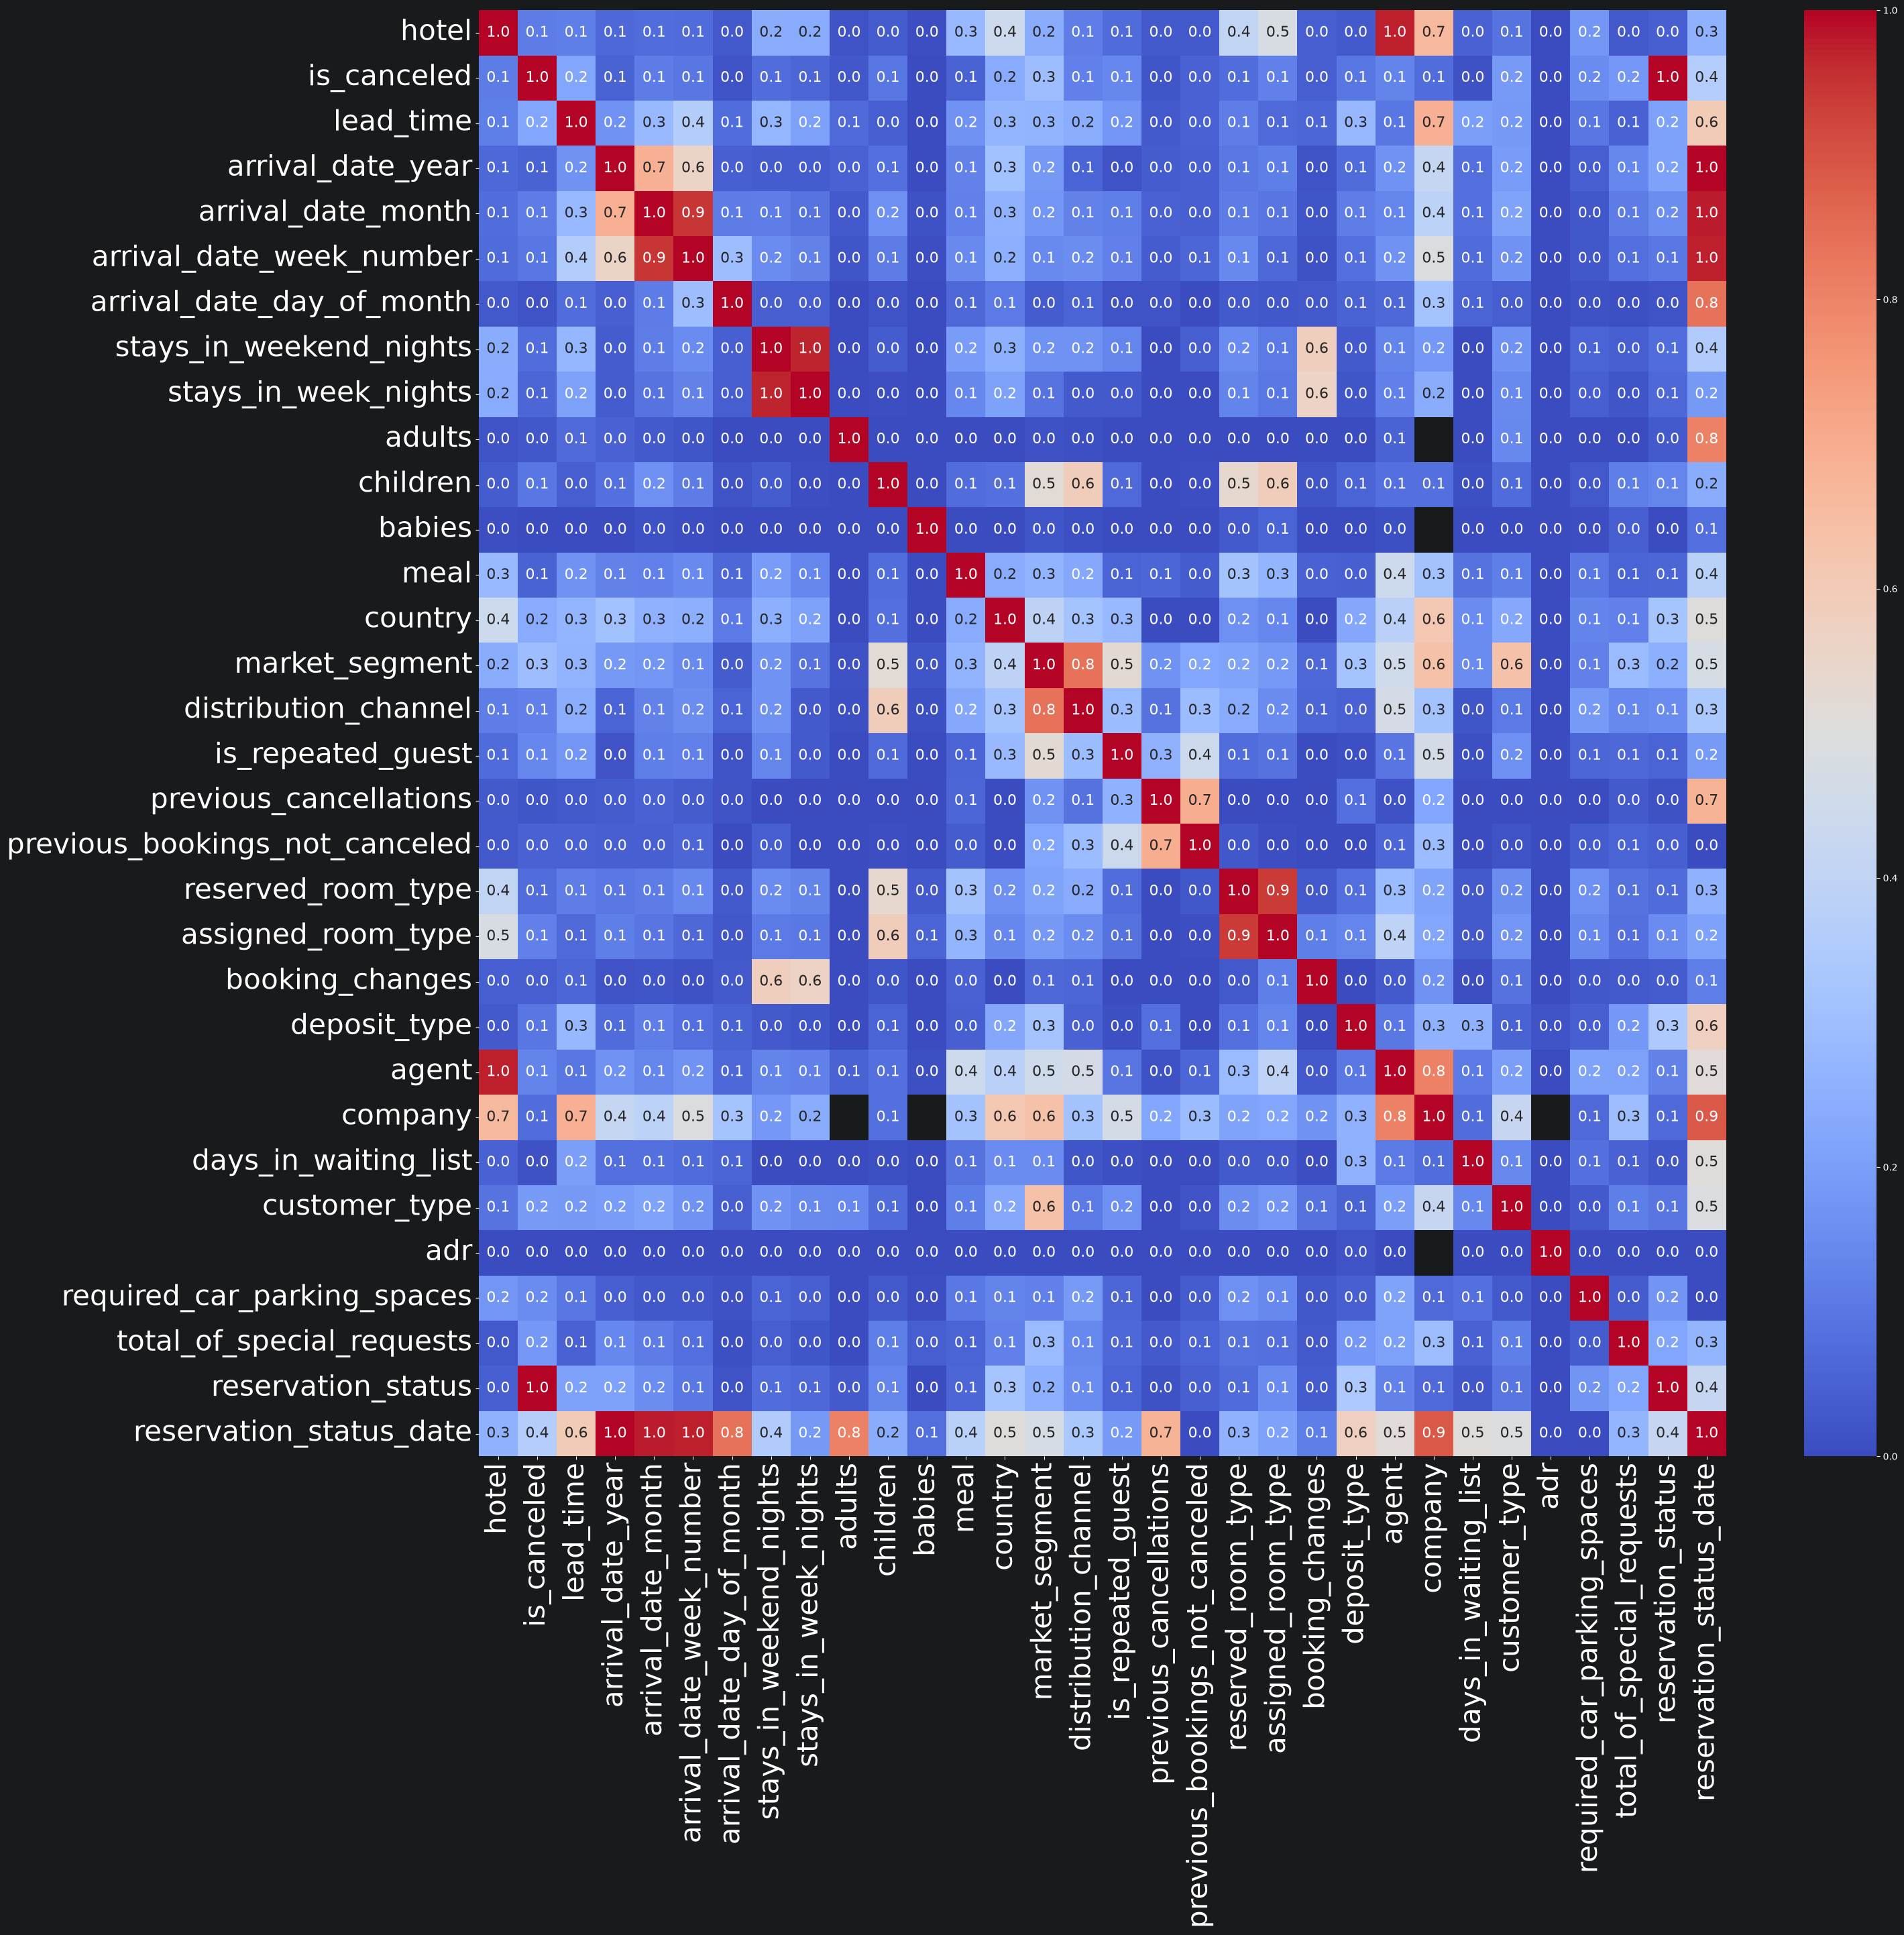

In [42]:
phik_ma = df.phik_matrix()
plt.figure(figsize=(30, 28))
sns.heatmap(phik_ma, annot=True, cmap="coolwarm", fmt=".1f", annot_kws={"size": 16})
plt.xticks(fontsize=30, rotation=90)
plt.yticks(fontsize=30)

interval columns not set, guessing: ['is_canceled', 'lead_time', 'stays_in_week_nights', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5, 20.5]),
 [Text(0, 0.5, 'hotel'),
  Text(0, 1.5, 'is_canceled'),
  Text(0, 2.5, 'lead_time'),
  Text(0, 3.5, 'stays_in_week_nights'),
  Text(0, 4.5, 'children'),
  Text(0, 5.5, 'babies'),
  Text(0, 6.5, 'meal'),
  Text(0, 7.5, 'country'),
  Text(0, 8.5, 'market_segment'),
  Text(0, 9.5, 'is_repeated_guest'),
  Text(0, 10.5, 'previous_cancellations'),
  Text(0, 11.5, 'previous_bookings_not_canceled'),
  Text(0, 12.5, 'reserved_room_type'),
  Text(0, 13.5, 'booking_changes'),
  Text(0, 14.5, 'deposit_type'),
  Text(0, 15.5, 'days_in_waiting_list'),
  Text(0, 16.5, 'customer_type'),
  Text(0, 17.5, 'adr'),
  Text(0, 18.5, 'required_car_parking_spaces'),
  Text(0, 19.5, 'total_of_special_requests'),
  Text(0, 20.5, 'reservation_status_date')])

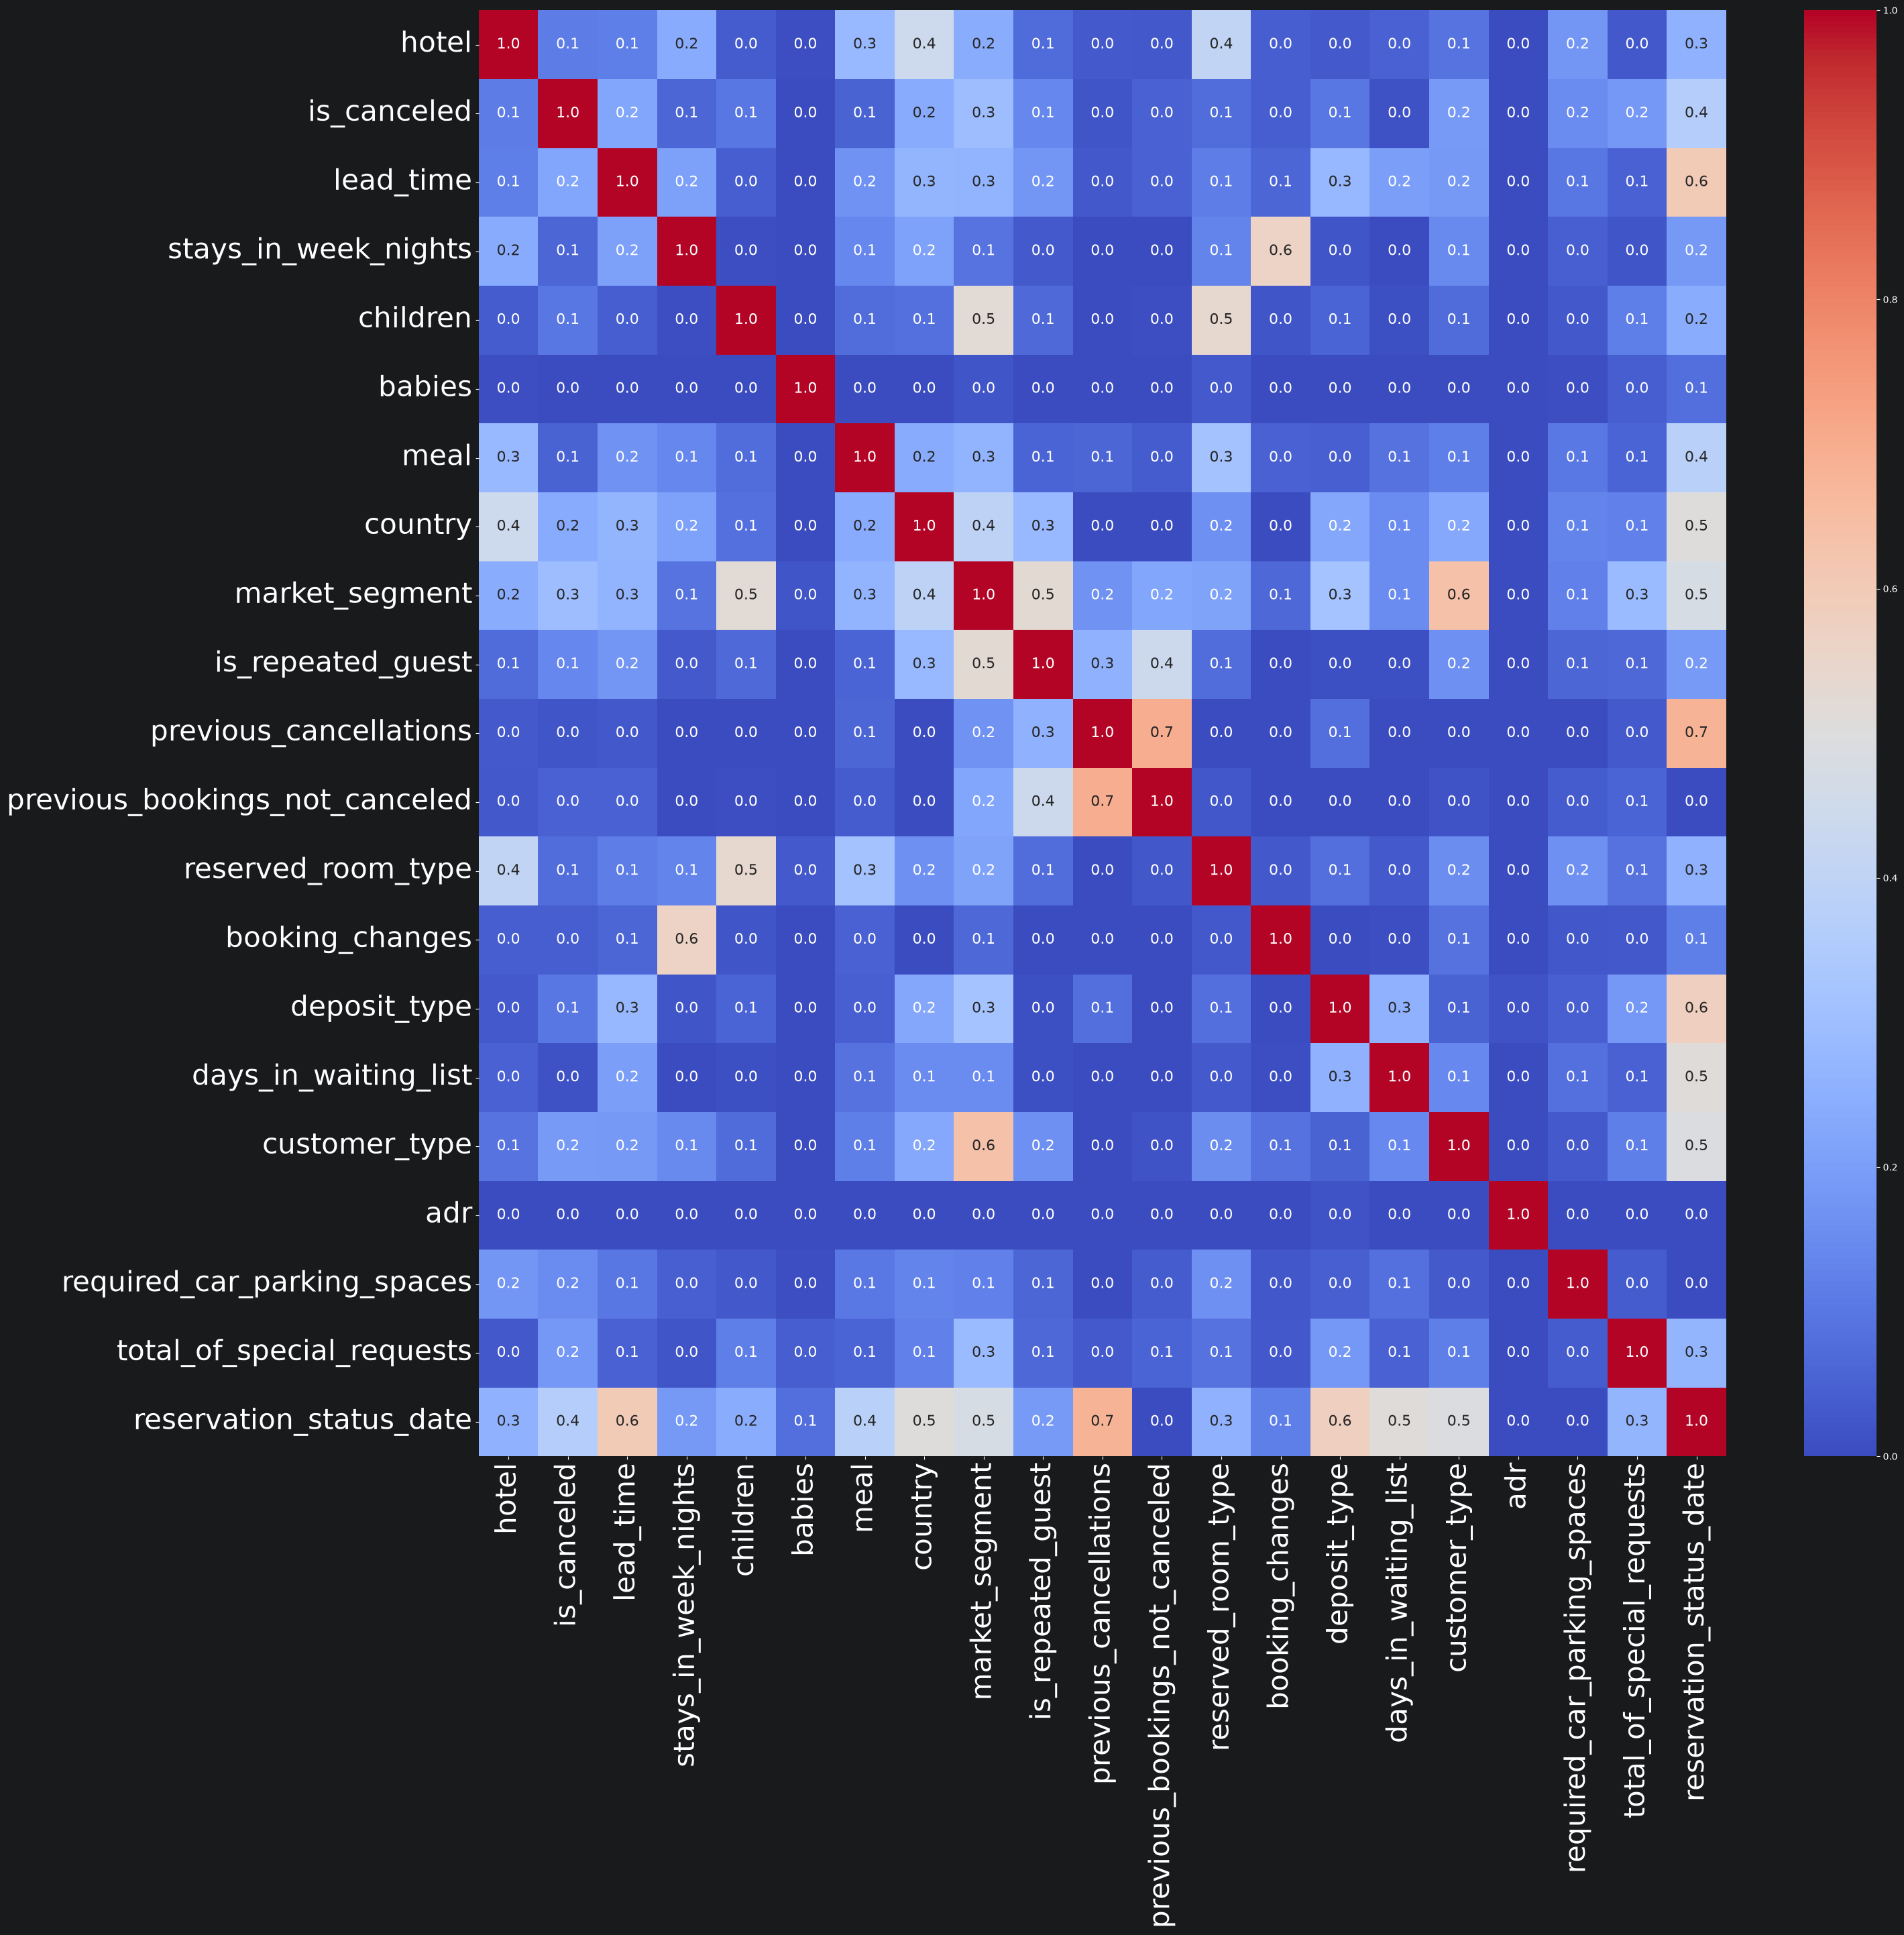

In [43]:
df = df.drop(columns=["arrival_date_year","arrival_date_month","arrival_date_week_number","arrival_date_day_of_month","adults","agent","company","assigned_room_type","distribution_channel", "reservation_status", "stays_in_weekend_nights"])
phik_ma = df.phik_matrix()
plt.figure(figsize=(30, 28))
sns.heatmap(phik_ma, annot=True, cmap="coolwarm", fmt=".1f", annot_kws={"size": 16})
plt.xticks(fontsize=30, rotation=90)
plt.yticks(fontsize=30)
